# Intuition Game of Chicken/BoS
Is the likelihood of miscoordination higher in the game of chicken with commitment? Misscoordination is any non-equilibrium outcome being reached.

In [1]:
def p_battle_of_sexes(b, c):
    numerator = b**2 * (b - 1)
    denominator = (b + c - 1) * (b**2 - b + c**2 - c)
    return numerator / denominator

def q_battle_of_sexes(b, c):
    p = p_battle_of_sexes(b, c)
    return (c - b - (1 - b) * p) / c

def q_game_of_chicken(b, c):
    numerator = c**2 - c
    denominator = c**2 - c + b**2 - b + b * c
    return numerator / denominator

In [2]:
def p_miscoordination_battle_of_sexes(b,c):
    p_wait_mis = (b / (b + c - 1))**2 + (1 - b / (b + c - 1))**2
    return p_battle_of_sexes(b,c)**2 + q_battle_of_sexes(b,c)**2 + (1-p_battle_of_sexes(b,c)-q_battle_of_sexes(b,c))**2 * p_wait_mis

def p_miscoordination_game_of_chicken(b,c):
    p_wait_mis = (b / (b + c - 1))**2 + (1 - b / (b + c - 1))**2
    return q_game_of_chicken(b,c)**2 + (1-q_game_of_chicken(b,c))**2 * p_wait_mis

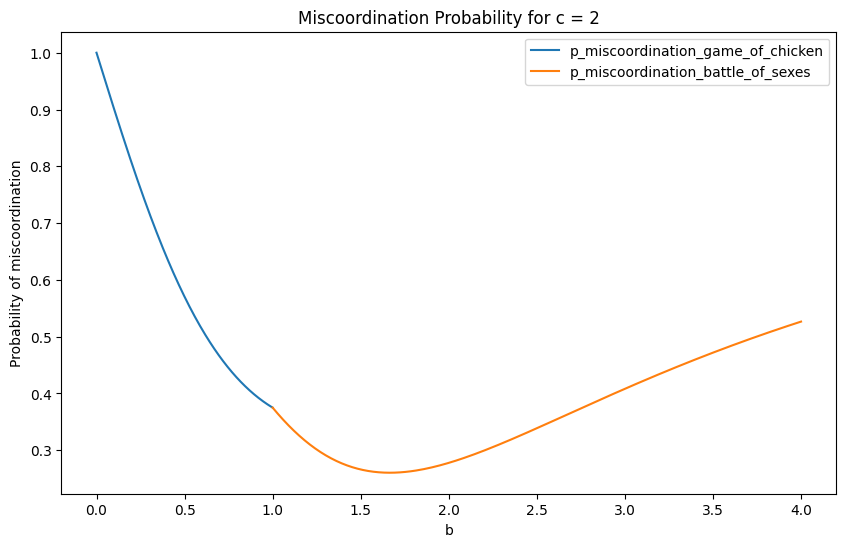

In [6]:
# For Game of Chicken: b in [0, 1]
b_chicken_new = np.linspace(0, 1, 200)
y_chicken_new = np.array([p_miscoordination_game_of_chicken(b, fixed_c) for b in b_chicken_new])

# For Battle of Sexes: b in [1, 2]
b_bos_new = np.linspace(1, 4, 200)
y_bos_new = np.array([p_miscoordination_battle_of_sexes(b, fixed_c) for b in b_bos_new])

plt.figure(figsize=(10, 6))
plt.plot(b_chicken_new, y_chicken_new, label="p_miscoordination_game_of_chicken")
plt.plot(b_bos_new, y_bos_new, label="p_miscoordination_battle_of_sexes")
plt.xlabel("b")
plt.ylabel("Probability of miscoordination")
plt.title(f"Miscoordination Probability for c = {fixed_c}")
plt.legend()
plt.show()


# Signalling

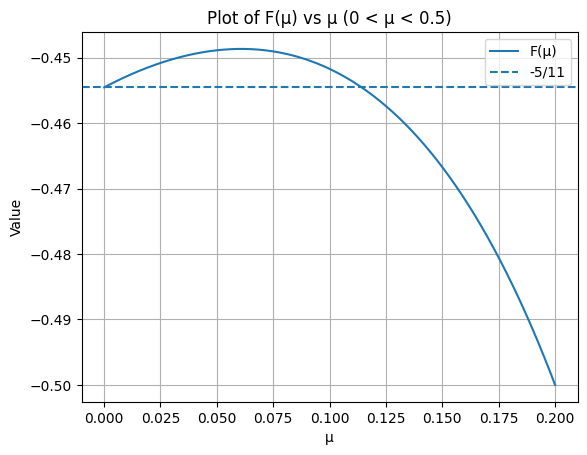

-0.5


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# expression from your note
def F(mu):
    return (1 - mu) * (3 * mu - 5) / (11 * (1 - mu)) + mu * (-2 - 23 * mu) / (22 * (1 - 2 * mu))

mu_vals = np.linspace(1e-4, 0.2, 1000)  # avoid the poles at 0 and 0.5
F_vals = F(mu_vals)

plt.figure()
plt.plot(mu_vals, F_vals, label="F(μ)")          # the expression
plt.axhline(-5/11, linestyle='--', label="-5/11") # horizontal reference
plt.xlabel("μ")
plt.ylabel("Value")
plt.title("Plot of F(μ) vs μ (0 < μ < 0.5)")
plt.legend()
plt.grid(True)
plt.show()

print(F(0.2))


# Proposition 1
### Battle of Sexes
b=2, c=3 leads to p=1/16, q=9/16

In [23]:
def compute_p(b: float, c: float) -> float:
    numerator = b * (b - 1)**2
    denominator = (b + c - 1) * (b**2 - b + c**2 - c)
    return numerator / denominator

def compute_q(b: float, c: float) -> float:
    numerator = c**2 * (c - 1)
    denominator = (b + c - 1) * (b**2 - b + c**2 - c)
    return numerator / denominator

print(compute_p(b=2, c=3))
print(1/16)
print(compute_q(2, 3))
print(9/16)


0.0625
0.0625
0.5625
0.5625


### Game of Chicken
b=2, c=0.5 leads to p=8/11

In [1]:
def p_equal(b: float, c: float) -> float:
    denom = c * (b + c - 1) + b * (b - 1)
    if denom == 0:
        raise ValueError("Undefined: requires b + c ≠ 1.")
    return b * (b - 1) / denom

print(p_equal(2, 0.5))
print(8/11)

0.7272727272727273
0.7272727272727273


### Coordination Game
b=c=-1 leads to p=8/15, q=1/15

In [24]:
def p_equilibrium(b: float, c: float) -> float:
    num = (b - 1) * (b * c - b - c + 1)
    den = (b + c - 1) * (2 * b * c - b - c + 1)
    if den == 0:
        raise ZeroDivisionError(
            "Denominator is zero; require b + c ≠ 1 and 2*b*c − b − c + 1 ≠ 0."
        )
    return num / den


def q_equilibrium(b: float, c: float) -> float:
    p = p_equilibrium(b, c)
    return (1 + p * (c - 1)) / b

print(p_equilibrium(-1, -1))
print(8/15)
print(q_equilibrium(-1, -1))
print(1/15)


0.5333333333333333
0.5333333333333333
0.06666666666666665
0.06666666666666667


# Propostion 2
### Battle of Sexes
b=2, c=3 leads to p=1/16, q=9/16

In [25]:
def p1(b: float, c: float, T: int) -> float:
    if b == 1 or c == 1:
        raise ValueError("b and c must both differ from 1 (division by zero).")
    if c == b:
        raise ValueError("c must differ from b (numerator would be zero).")

    ratio = (c * (c - 1)) / (b * (b - 1))          # (c(c-1))/(b(b-1))
    denominator = c * (c - 1) / (b - 1) * ratio**T - b
    return (c - b) / denominator

print(p1(b = 2, c = 3, T = 1))
print(1/16)


0.0625
0.0625
